![EmoSense AI Banner](https://github.com/elkeshawy-Moh/EmoSense-AI-Emotion-Classification/blob/main/banner.png?raw=true)

# 🎭 EmoSense AI: Multi-Class Emotion Classification with Attention & Transformers

### 📌 Project Overview
Understanding human emotion in text is a fundamental task in Natural Language Processing (NLP) with applications in sentiment analysis, empathetic conversational agents, and mental health monitoring. This project builds, evaluates, and deploys a multi-class emotion classification pipeline capable of categorizing English text into **six core Ekman emotions**: **Joy, Sadness, Anger, Fear, Surprise, and Disgust**.

---

### 🗂️ Dataset & Methodology
* **Dataset:** [GoEmotions](https://huggingface.co) (Google Research) — 54,300+ simplified Reddit comments mapped from 27 fine-grained emotion categories into 6 core target classes.
* **Imbalance Handling:** Applied inverse class weighting (`compute_class_weight`) inside the Cross-Entropy loss function to prevent majority-class bias.
* **Word Representations:** Initialized sequence models with pre-trained 100-dimensional **GloVe** embeddings (`glove-wiki-gigaword-100`).

---

### 🧠 Model Architectures Evaluated
1. **LSTM (Baseline):** Standard recurrent network with masked mean pooling.
2. **GRU:** Gated Recurrent Unit architecture with masked mean pooling.
3. **BiLSTM + Self-Attention:** Bidirectional LSTM enhanced with a custom attention mechanism to weight key emotional tokens and generate **Attention Heatmaps** for model interpretability.
4. **Fine-Tuned DistilBERT:** Pre-trained transformer fine-tuned via the Hugging Face `Trainer` API.

---

### 📊 Key Experimental Results (Test Set)

| Architecture | Test Accuracy | Test Macro F1 |
| :--- | :---: | :---: |
| **GRU** | 66.32% | 0.5730 |
| **LSTM** | 68.73% | 0.5852 |
| **BiLSTM + Attention** | 70.34% | 0.6083 |
| **DistilBERT (Fine-Tuned)** | **77.88%** | **0.6910** |

---

### 🚀 Deployment
The top-performing **DistilBERT** model is deployed at the end of this notebook as an interactive **Gradio Web Application**, providing real-time dominant emotion prediction alongside a multi-class confidence distribution chart.


# Step 1:Install required libraries

In [1]:
# Install required libraries if not already available
!pip install -q datasets transformers accelerate gradio

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

# Load the simplified version of GoEmotions dataset
dataset = load_dataset("google-research-datasets/go_emotions", "simplified")

# Check the splits and dataset structure
print(dataset)


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

simplified/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5427
    })
})


# Step 2:Original 28 labels in GoEmotions simplified configuration

Train samples: 23485, Val samples: 2956, Test samples: 2984


/tmp/ipykernel_50/1868206697.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train_df, x='emotion', order=target_classes, palette='viridis')


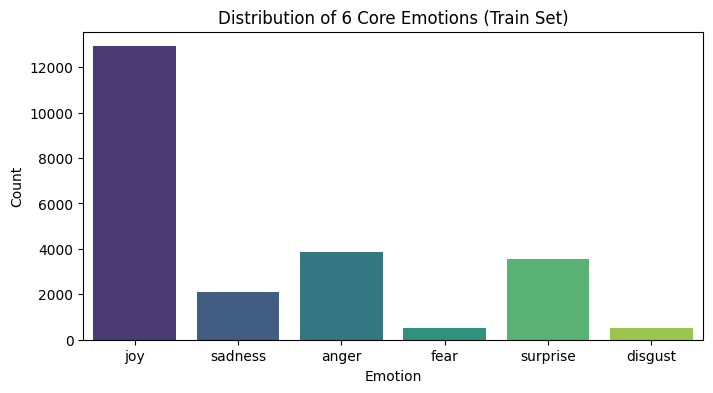

In [3]:
# Original 28 labels in GoEmotions simplified configuration
original_labels = dataset['train'].features['labels'].feature.names

# Ekman mapping: Map the 27 fine-grained emotions to the 6 core emotions
ekman_mapping = {
    'joy': ['joy', 'amusement', 'approval', 'excitement', 'gratitude', 'love', 'optimism', 'relief', 'pride', 'admiration', 'desire', 'caring'],
    'sadness': ['sadness', 'disappointment', 'embarrassment', 'grief', 'remorse'],
    'anger': ['anger', 'annoyance', 'disapproval'],
    'fear': ['fear', 'nervousness'],
    'surprise': ['surprise', 'realization', 'confusion', 'curiosity'],
    'disgust': ['disgust']
}

# Create a reverse lookup dictionary from original label index to target emotion name
id_to_ekman = {}
for target_emotion, sub_emotions in ekman_mapping.items():
    for sub in sub_emotions:
        idx = original_labels.index(sub)
        id_to_ekman[idx] = target_emotion

# Target class encoding
target_classes = ['joy', 'sadness', 'anger', 'fear', 'surprise', 'disgust']
label2id = {label: i for i, label in enumerate(target_classes)}
id2label = {i: label for i, label in enumerate(target_classes)}

def filter_and_map_data(split_data):
    records = []
    for item in split_data:
        # Keep single-label examples that map cleanly to our 6 target emotions
        if len(item['labels']) == 1:
            orig_id = item['labels'][0]
            if orig_id in id_to_ekman:
                mapped_emotion = id_to_ekman[orig_id]
                records.append({
                    'text': item['text'],
                    'emotion': mapped_emotion,
                    'label': label2id[mapped_emotion]
                })
    return pd.DataFrame(records)

# Process train, validation, and test splits
train_df = filter_and_map_data(dataset['train'])
val_df = filter_and_map_data(dataset['validation'])
test_df = filter_and_map_data(dataset['test'])

print(f"Train samples: {len(train_df)}, Val samples: {len(val_df)}, Test samples: {len(test_df)}")

# Plot the class distribution in the training set
plt.figure(figsize=(8, 4))
sns.countplot(data=train_df, x='emotion', order=target_classes, palette='viridis')
plt.title("Distribution of 6 Core Emotions (Train Set)")
plt.xlabel("Emotion")
plt.ylabel("Count")
plt.show()


# Step 3 :Text cleaning, dictionary building, and GloVe matrix preparation

In [4]:
import re
import torch
from torch.utils.data import Dataset, DataLoader
from collections import Counter

# Set random seeds for reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Define device (GPU if available)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

def clean_text(text):
    # Convert text to lowercase
    text = text.lower()
    # Remove URLs and user mentions
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)
    text = re.sub(r'\[name\]|\[religion\]', '', text)
    # Keep letters, spaces, and basic emotional punctuation (! ?)
    text = re.sub(r"[^a-z\s!?']", '', text)
    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Apply text cleaning to all splits
train_df['clean_text'] = train_df['text'].apply(clean_text)
val_df['clean_text'] = val_df['text'].apply(clean_text)
test_df['clean_text'] = test_df['text'].apply(clean_text)

# Build vocabulary from the training set
MAX_VOCAB_SIZE = 15000
MAX_LEN = 50

word_counts = Counter()
for text in train_df['clean_text']:
    word_counts.update(text.split())

# Reserve 0 for <PAD> and 1 for <UNK> (unknown words)
vocab = {'<PAD>': 0, '<UNK>': 1}
for word, _ in word_counts.most_common(MAX_VOCAB_SIZE - 2):
    vocab[word] = len(vocab)

print(f"Vocabulary size: {len(vocab)}")

def encode_and_pad(text, vocab, max_len):
    tokens = text.split()
    encoded = [vocab.get(word, vocab['<UNK>']) for word in tokens]
    # Truncate or pad sequence to fixed length
    if len(encoded) < max_len:
        encoded += [vocab['<PAD>']] * (max_len - len(encoded))
    else:
        encoded = encoded[:max_len]
    return encoded

# Create PyTorch Dataset class
class EmotionDataset(Dataset):
    def __init__(self, df, vocab, max_len):
        self.sequences = [encode_and_pad(t, vocab, max_len) for t in df['clean_text']]
        self.labels = df['label'].values

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return (
            torch.tensor(self.sequences[idx], dtype=torch.long),
            torch.tensor(self.labels[idx], dtype=torch.long)
        )

# Initialize Datasets and DataLoaders
BATCH_SIZE = 64
train_dataset = EmotionDataset(train_df, vocab, MAX_LEN)
val_dataset = EmotionDataset(val_df, vocab, MAX_LEN)
test_dataset = EmotionDataset(test_df, vocab, MAX_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE)

print("DataLoaders created successfully!")


Using device: cuda
Vocabulary size: 15000
DataLoaders created successfully!


# Step 4:GloVe upload code and embed array construction

In [17]:
import os
import gensim.downloader as api
import numpy as np
import torch

# 1. Clean up the old broken zip file
zip_path = "/kaggle/working/glove.6B.zip"
if os.path.exists(zip_path):
  os.remove(zip_path)

# 2. Load 100d GloVe embeddings directly via gensim (no URLs or zip extraction needed)
print("Downloading/Loading GloVe 100d embeddings...")
glove_vectors = api.load("glove-wiki-gigaword-100")
print(f"Loaded {len(glove_vectors):,} word vectors from GloVe.")

# 3. Construct the Embedding Matrix matching your 'vocab' dictionary
EMBED_DIM = 100
vocab_size = len(vocab)
embedding_matrix = np.zeros((vocab_size, EMBED_DIM), dtype="float32")

hits = 0
misses = 0

for word, idx in vocab.items():
  if word == "<PAD>":
    continue  # Keep <PAD> row as all zeros
  if word in glove_vectors:
    embedding_matrix[idx] = glove_vectors[word]
    hits += 1
  else:
    # Initialize unknown words randomly with small variance
    embedding_matrix[idx] = np.random.normal(scale=0.6, size=(EMBED_DIM,))
    misses += 1

# 4. Convert to PyTorch tensor ready for nn.Embedding.from_pretrained()
embedding_tensor = torch.tensor(embedding_matrix, dtype=torch.float32)

print(f"Embedding matrix shape: {embedding_tensor.shape}")
print(f"Matched words: {hits:,} | Unknown words: {misses:,}")


Downloading/Loading GloVe 100d embeddings...
[==================================================] 100.0% 128.1/128.1MB downloaded
Loaded 400,000 word vectors from GloVe.
Embedding matrix shape: torch.Size([15000, 100])
Matched words: 11,641 | Unknown words: 3,358


# Step 5:Building and training the three models (LSTM, GRU and BiLSTM + Attention)

In [18]:
import torch.nn as nn
import torch.optim as optim
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# 1. Compute balanced class weights to handle dataset imbalance
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_df['label']),
    y=train_df['label']
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

# 2. Define Standard LSTM Classifier
class LSTMClassifier(nn.Module):
    def __init__(self, embedding_matrix, hidden_dim, output_dim, dropout=0.3):
        super().__init__()
        num_embeddings, embed_dim = embedding_matrix.shape
        self.embedding = nn.Embedding.from_pretrained(embedding_matrix, freeze=False, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, text):
        embedded = self.dropout(self.embedding(text))
        _, (hidden, _) = self.lstm(embedded)
        out = self.dropout(hidden[-1])
        return self.fc(out)

# 3. Define Standard GRU Classifier
class GRUClassifier(nn.Module):
    def __init__(self, embedding_matrix, hidden_dim, output_dim, dropout=0.3):
        super().__init__()
        num_embeddings, embed_dim = embedding_matrix.shape
        self.embedding = nn.Embedding.from_pretrained(embedding_matrix, freeze=False, padding_idx=0)
        self.gru = nn.GRU(embed_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, text):
        embedded = self.dropout(self.embedding(text))
        _, hidden = self.gru(embedded)
        out = self.dropout(hidden[-1])
        return self.fc(out)

# 4. Define BiLSTM + Attention Classifier
class Attention(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        # hidden_dim * 2 because BiLSTM is bidirectional
        self.attn = nn.Linear(hidden_dim * 2, 1)

    def forward(self, lstm_output, mask=None):
        # lstm_output shape: [batch_size, seq_len, hidden_dim * 2]
        scores = self.attn(torch.tanh(lstm_output)).squeeze(-1)
        if mask is not None:
            scores = scores.masked_fill(mask == 0, -1e9)
        attn_weights = torch.softmax(scores, dim=1)
        # Weighted sum of hidden states
        context = torch.bmm(attn_weights.unsqueeze(1), lstm_output).squeeze(1)
        return context, attn_weights

class BiLSTMAttentionClassifier(nn.Module):
    def __init__(self, embedding_matrix, hidden_dim, output_dim, dropout=0.3):
        super().__init__()
        num_embeddings, embed_dim = embedding_matrix.shape
        self.embedding = nn.Embedding.from_pretrained(embedding_matrix, freeze=False, padding_idx=0)
        self.bilstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.attention = Attention(hidden_dim)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * 2, output_dim)

    def forward(self, text, return_attention=False):
        mask = (text != 0)
        embedded = self.dropout(self.embedding(text))
        lstm_out, _ = self.bilstm(embedded)
        context, attn_weights = self.attention(lstm_out, mask)
        out = self.dropout(context)
        logits = self.fc(out)
        if return_attention:
            return logits, attn_weights
        return logits

print("Model architectures defined successfully!")


Model architectures defined successfully!


# Step 6:Training and evaluation code for the three models

In [19]:
def train_and_evaluate(model, model_name, train_loader, val_loader, test_loader, epochs=6, lr=1e-3):
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    best_val_f1 = 0.0
    best_path = f"{model_name}_best.pt"

    print(f"\n--- Training {model_name} ---")
    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for texts, labels in train_loader:
            texts, labels = texts.to(device), labels.to(device)
            optimizer.zero_grad()
            predictions = model(texts)
            loss = criterion(predictions, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        # Validation phase
        model.eval()
        val_preds, val_targets = [], []
        with torch.no_grad():
            for texts, labels in val_loader:
                texts = texts.to(device)
                outputs = model(texts)
                preds = torch.argmax(outputs, dim=1).cpu().numpy()
                val_preds.extend(preds)
                val_targets.extend(labels.numpy())

        val_acc = accuracy_score(val_targets, val_preds)
        val_f1 = f1_score(val_targets, val_preds, average='macro')
        print(f"Epoch {epoch+1}/{epochs} | Loss: {total_loss/len(train_loader):.4f} | Val Acc: {val_acc:.4f} | Val Macro F1: {val_f1:.4f}")

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            torch.save(model.state_dict(), best_path)

    # Load best weights for final test evaluation
    model.load_state_dict(torch.load(best_path))
    model.eval()
    test_preds, test_targets = [], []
    with torch.no_grad():
        for texts, labels in test_loader:
            texts = texts.to(device)
            outputs = model(texts)
            preds = torch.argmax(outputs, dim=1).cpu().numpy()
            test_preds.extend(preds)
            test_targets.extend(labels.numpy())

    test_acc = accuracy_score(test_targets, test_preds)
    test_f1 = f1_score(test_targets, test_preds, average='macro')
    print(f"[{model_name} Test Results] Accuracy: {test_acc:.4f} | Macro F1: {test_f1:.4f}")
    return model, test_acc, test_f1, test_preds, test_targets

# Dictionary to store evaluation results for all models
results_summary = {}

HIDDEN_DIM = 128
OUTPUT_DIM = len(target_classes)

# Train LSTM
lstm_model = LSTMClassifier(embedding_tensor, HIDDEN_DIM, OUTPUT_DIM)
lstm_model, acc, f1, preds, targets = train_and_evaluate(lstm_model, "LSTM", train_loader, val_loader, test_loader)
results_summary["LSTM"] = {"Accuracy": acc, "Macro F1": f1, "preds": preds, "targets": targets}

# Train GRU
gru_model = GRUClassifier(embedding_tensor, HIDDEN_DIM, OUTPUT_DIM)
gru_model, acc, f1, preds, targets = train_and_evaluate(gru_model, "GRU", train_loader, val_loader, test_loader)
results_summary["GRU"] = {"Accuracy": acc, "Macro F1": f1, "preds": preds, "targets": targets}

# Train BiLSTM + Attention
bilstm_attn_model = BiLSTMAttentionClassifier(embedding_tensor, HIDDEN_DIM, OUTPUT_DIM)
bilstm_attn_model, acc, f1, preds, targets = train_and_evaluate(bilstm_attn_model, "BiLSTM_Attention", train_loader, val_loader, test_loader)
results_summary["BiLSTM + Attention"] = {"Accuracy": acc, "Macro F1": f1, "preds": preds, "targets": targets}



--- Training LSTM ---
Epoch 1/6 | Loss: 1.7920 | Val Acc: 0.1641 | Val Macro F1: 0.0470
Epoch 2/6 | Loss: 1.7914 | Val Acc: 0.1641 | Val Macro F1: 0.0470
Epoch 3/6 | Loss: 1.7908 | Val Acc: 0.0815 | Val Macro F1: 0.0251
Epoch 4/6 | Loss: 1.7911 | Val Acc: 0.5643 | Val Macro F1: 0.1202
Epoch 5/6 | Loss: 1.7908 | Val Acc: 0.5643 | Val Macro F1: 0.1202
Epoch 6/6 | Loss: 1.7915 | Val Acc: 0.5643 | Val Macro F1: 0.1202
[LSTM Test Results] Accuracy: 0.5372 | Macro F1: 0.1165

--- Training GRU ---
Epoch 1/6 | Loss: 1.7929 | Val Acc: 0.0815 | Val Macro F1: 0.0251
Epoch 2/6 | Loss: 1.7923 | Val Acc: 0.1472 | Val Macro F1: 0.0428
Epoch 3/6 | Loss: 1.7921 | Val Acc: 0.1641 | Val Macro F1: 0.0470
Epoch 4/6 | Loss: 1.7910 | Val Acc: 0.1472 | Val Macro F1: 0.0428
Epoch 5/6 | Loss: 1.7916 | Val Acc: 0.1472 | Val Macro F1: 0.0428
Epoch 6/6 | Loss: 1.7452 | Val Acc: 0.4760 | Val Macro F1: 0.2375
[GRU Test Results] Accuracy: 0.4682 | Macro F1: 0.2401

--- Training BiLSTM_Attention ---
Epoch 1/6 | Loss:

# Step 7:Improved LSTM and GRU using masked mean pooling instead of final padded step

In [21]:
class ImprovedLSTMClassifier(nn.Module):
    def __init__(self, embedding_matrix, hidden_dim, output_dim, dropout=0.3):
        super().__init__()
        num_embeddings, embed_dim = embedding_matrix.shape
        self.embedding = nn.Embedding.from_pretrained(embedding_matrix, freeze=False, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, text):
        mask = (text != 0).unsqueeze(-1).float()
        embedded = self.dropout(self.embedding(text))
        lstm_out, _ = self.lstm(embedded)
        # Compute mean over non-padded tokens only
        pooled = (lstm_out * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)
        return self.fc(self.dropout(pooled))

class ImprovedGRUClassifier(nn.Module):
    def __init__(self, embedding_matrix, hidden_dim, output_dim, dropout=0.3):
        super().__init__()
        num_embeddings, embed_dim = embedding_matrix.shape
        self.embedding = nn.Embedding.from_pretrained(embedding_matrix, freeze=False, padding_idx=0)
        self.gru = nn.GRU(embed_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, text):
        mask = (text != 0).unsqueeze(-1).float()
        embedded = self.dropout(self.embedding(text))
        gru_out, _ = self.gru(embedded)
        pooled = (gru_out * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)
        return self.fc(self.dropout(pooled))

# Re-train LSTM and GRU with clean pooling
lstm_model = ImprovedLSTMClassifier(embedding_tensor, HIDDEN_DIM, OUTPUT_DIM)
lstm_model, acc, f1, preds, targets = train_and_evaluate(lstm_model, "LSTM", train_loader, val_loader, test_loader)
results_summary["LSTM"] = {"Accuracy": acc, "Macro F1": f1, "preds": preds, "targets": targets}

gru_model = ImprovedGRUClassifier(embedding_tensor, HIDDEN_DIM, OUTPUT_DIM)
gru_model, acc, f1, preds, targets = train_and_evaluate(gru_model, "GRU", train_loader, val_loader, test_loader)
results_summary["GRU"] = {"Accuracy": acc, "Macro F1": f1, "preds": preds, "targets": targets}



--- Training LSTM ---
Epoch 1/6 | Loss: 1.6290 | Val Acc: 0.5673 | Val Macro F1: 0.4331
Epoch 2/6 | Loss: 1.2734 | Val Acc: 0.6390 | Val Macro F1: 0.5313
Epoch 3/6 | Loss: 1.0740 | Val Acc: 0.6505 | Val Macro F1: 0.5566
Epoch 4/6 | Loss: 0.9496 | Val Acc: 0.6989 | Val Macro F1: 0.5824
Epoch 5/6 | Loss: 0.8401 | Val Acc: 0.6752 | Val Macro F1: 0.5655
Epoch 6/6 | Loss: 0.7566 | Val Acc: 0.6952 | Val Macro F1: 0.5774
[LSTM Test Results] Accuracy: 0.6873 | Macro F1: 0.5852

--- Training GRU ---
Epoch 1/6 | Loss: 1.5833 | Val Acc: 0.5440 | Val Macro F1: 0.4477
Epoch 2/6 | Loss: 1.2069 | Val Acc: 0.6143 | Val Macro F1: 0.5185
Epoch 3/6 | Loss: 1.0388 | Val Acc: 0.6878 | Val Macro F1: 0.5625
Epoch 4/6 | Loss: 0.9207 | Val Acc: 0.6691 | Val Macro F1: 0.5726
Epoch 5/6 | Loss: 0.8222 | Val Acc: 0.6377 | Val Macro F1: 0.5287
Epoch 6/6 | Loss: 0.7269 | Val Acc: 0.6478 | Val Macro F1: 0.5348
[GRU Test Results] Accuracy: 0.6632 | Macro F1: 0.5730


# Step 8:DistilBERT Training and Assessment Code

In [22]:
import os
from datasets import Dataset as HFDataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

# Disable wandb logging to prevent interactive prompt interruption
os.environ["WANDB_DISABLED"] = "true"

MODEL_CHECKPOINT = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

# Convert pandas DataFrames to Hugging Face Datasets
hf_train = HFDataset.from_pandas(train_df[['text', 'label']])
hf_val = HFDataset.from_pandas(val_df[['text', 'label']])
hf_test = HFDataset.from_pandas(test_df[['text', 'label']])

def tokenize_function(examples):
    return tokenizer(examples["text"], truncation=True, max_length=64)

tokenized_train = hf_train.map(tokenize_function, batched=True)
tokenized_val = hf_val.map(tokenize_function, batched=True)
tokenized_test = hf_test.map(tokenize_function, batched=True)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Load pre-trained DistilBERT with 6 output labels
bert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=len(target_classes),
    id2label=id2label,
    label2id=label2id
)

# Define evaluation metrics function for Trainer
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, predictions)
    f1 = f1_score(labels, predictions, average="macro")
    return {"accuracy": acc, "macro_f1": f1}

# Custom Trainer to apply class weights for imbalanced emotions
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        loss_fct = nn.CrossEntropyLoss(weight=class_weights_tensor)
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

training_args = TrainingArguments(
    output_dir="./distilbert_results",
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    logging_steps=200,
    report_to="none"
)

trainer = WeightedTrainer(
    model=bert_model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

# Fine-tune DistilBERT
print("--- Fine-tuning DistilBERT ---")
trainer.train()

# Evaluate on test dataset
test_output = trainer.predict(tokenized_test)
bert_preds = np.argmax(test_output.predictions, axis=-1)
bert_targets = test_output.label_ids

bert_acc = accuracy_score(bert_targets, bert_preds)
bert_f1 = f1_score(bert_targets, bert_preds, average="macro")
print(f"\n[DistilBERT Test Results] Accuracy: {bert_acc:.4f} | Macro F1: {bert_f1:.4f}")

# Save results and final model for deployment
results_summary["DistilBERT (Fine-tuned)"] = {
    "Accuracy": bert_acc,
    "Macro F1": bert_f1,
    "preds": bert_preds,
    "targets": bert_targets
}

SAVE_DIR = "./final_emotion_distilbert"
trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
print(f"Final DistilBERT model saved to {SAVE_DIR}")


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/23485 [00:00<?, ? examples/s]

Map:   0%|          | 0/2956 [00:00<?, ? examples/s]

... (9 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


[DistilBERT Test Results] Accuracy: 0.7788 | Macro F1: 0.6910


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Final DistilBERT model saved to ./final_emotion_distilbert


# Step 9:Comprehensive assessment, confusion matrix, and attention heatmaps

=== Final Model Comparison Table ===
                  Model  Test Accuracy  Test Macro F1
DistilBERT (Fine-tuned)         0.7788         0.6910
     BiLSTM + Attention         0.7034         0.6083
                   LSTM         0.6873         0.5852
                    GRU         0.6632         0.5730


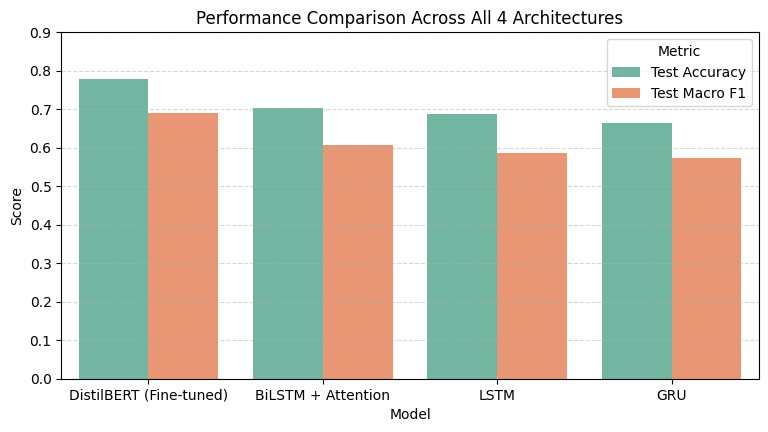


=== Per-Class Classification Report: BiLSTM + Attention ===
              precision    recall  f1-score   support

         joy     0.9028    0.7648    0.8281      1603
     sadness     0.4943    0.6718    0.5696       259
       anger     0.5937    0.5788    0.5862       520
        fear     0.5234    0.7273    0.6087        77
    surprise     0.5611    0.6548    0.6043       449
     disgust     0.3529    0.6316    0.4528        76

    accuracy                         0.7034      2984
   macro avg     0.5714    0.6715    0.6083      2984
weighted avg     0.7383    0.7034    0.7146      2984


=== Per-Class Classification Report: DistilBERT (Fine-tuned) ===
              precision    recall  f1-score   support

         joy     0.9265    0.8497    0.8864      1603
     sadness     0.5509    0.7104    0.6206       259
       anger     0.6654    0.6538    0.6596       520
        fear     0.6117    0.8182    0.7000        77
    surprise     0.7077    0.7171    0.7124       449
     

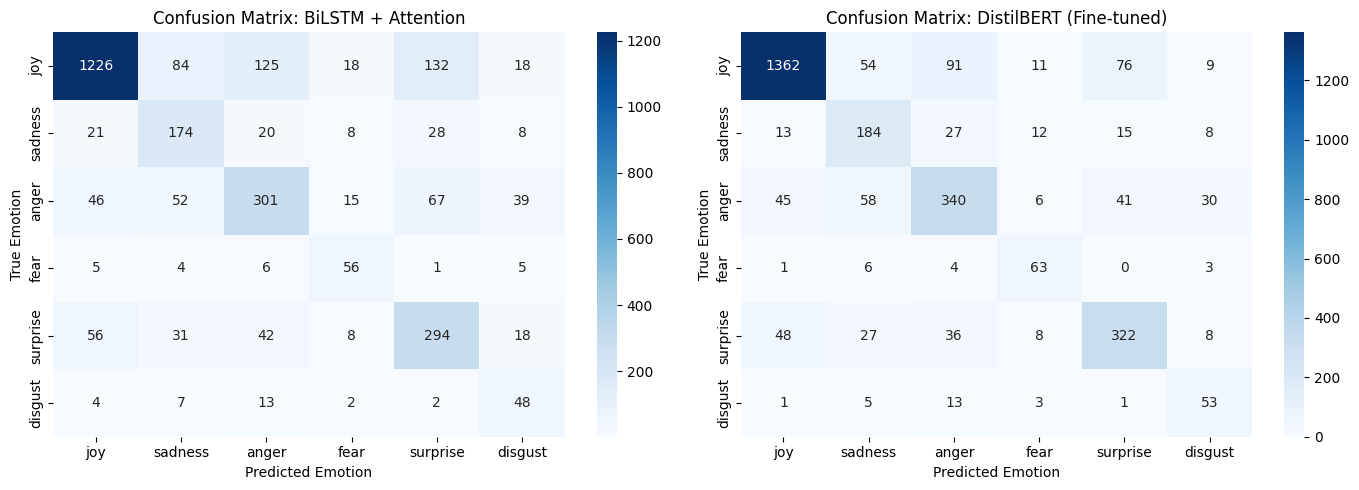

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Build a clean comparison table for all 4 architectures
comparison_data = []
for model_name, metrics in results_summary.items():
    comparison_data.append({
        "Model": model_name,
        "Test Accuracy": round(metrics["Accuracy"], 4),
        "Test Macro F1": round(metrics["Macro F1"], 4)
    })

comparison_df = pd.DataFrame(comparison_data).sort_values(by="Test Macro F1", ascending=False)
print("=== Final Model Comparison Table ===")
print(comparison_df.to_string(index=False))

# 2. Plot bar chart comparing Accuracy and Macro F1 across models
df_melted = comparison_df.melt(id_vars="Model", var_name="Metric", value_name="Score")
plt.figure(figsize=(9, 4.5))
sns.barplot(data=df_melted, x="Model", y="Score", hue="Metric", palette="Set2")
plt.title("Performance Comparison Across All 4 Architectures")
plt.ylim(0, 0.9)
plt.ylabel("Score")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

# 3. Print Per-Class Precision, Recall, and F1 for the top two models
for top_model in ["BiLSTM + Attention", "DistilBERT (Fine-tuned)"]:
    print(f"\n=== Per-Class Classification Report: {top_model} ===")
    targets = results_summary[top_model]["targets"]
    preds = results_summary[top_model]["preds"]
    print(classification_report(targets, preds, target_names=target_classes, digits=4))

# 4. Plot side-by-side Confusion Matrices for BiLSTM + Attention and DistilBERT
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, model_name in zip(axes, ["BiLSTM + Attention", "DistilBERT (Fine-tuned)"]):
    cm = confusion_matrix(results_summary[model_name]["targets"], results_summary[model_name]["preds"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=target_classes, yticklabels=target_classes, ax=ax)
    ax.set_title(f"Confusion Matrix: {model_name}")
    ax.set_xlabel("Predicted Emotion")
    ax.set_ylabel("True Emotion")

plt.tight_layout()
plt.show()


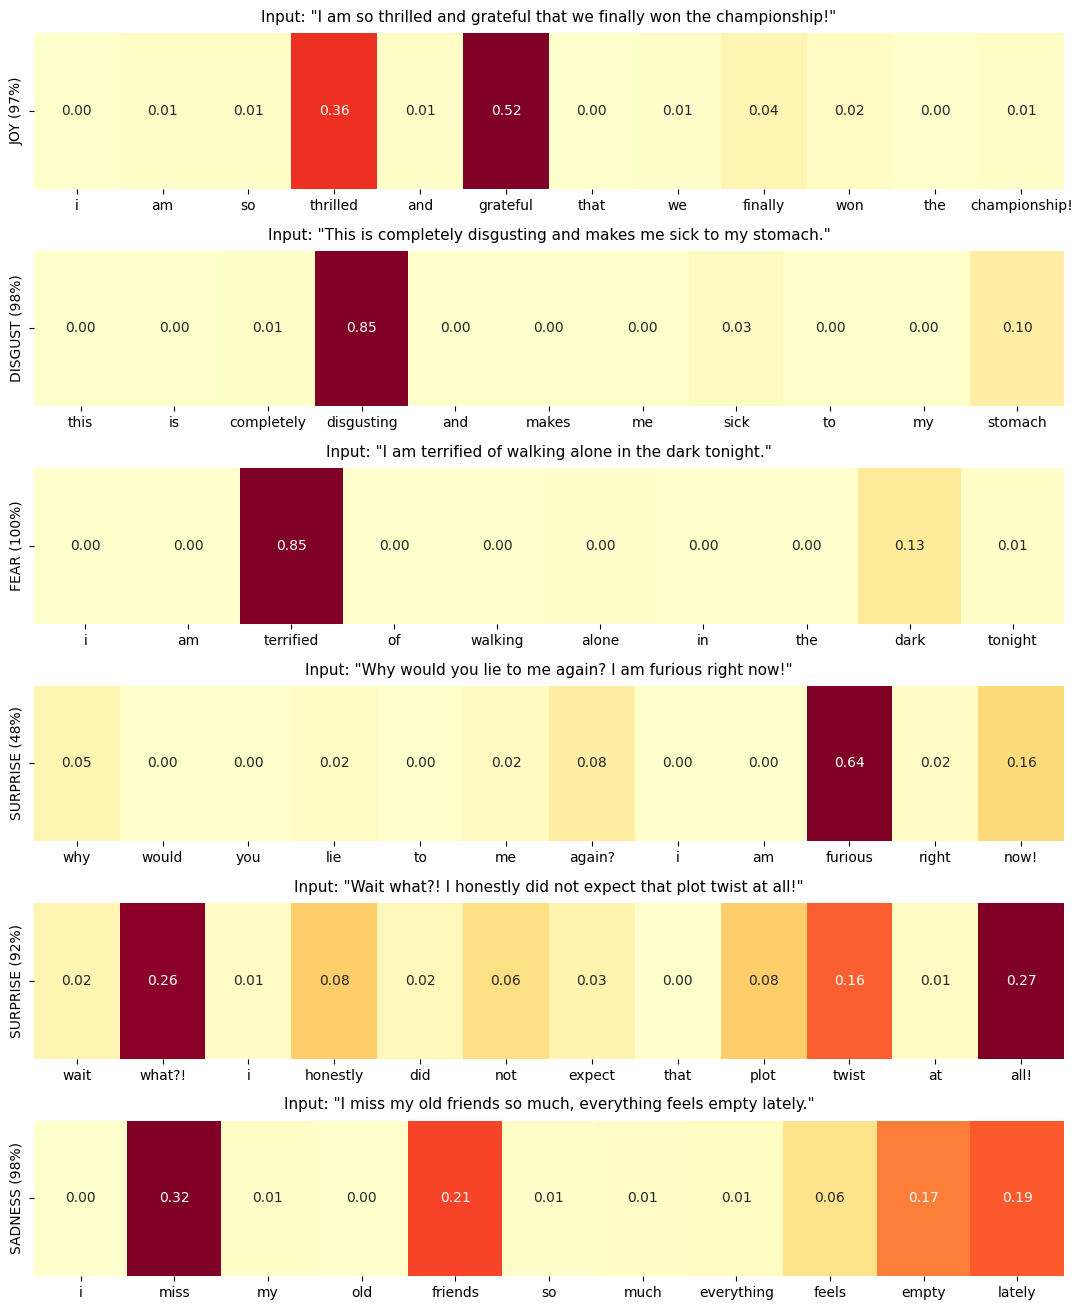

In [24]:
def plot_attention_heatmap(sentences, model, vocab, max_len=50):
    model.eval()
    fig, axes = plt.subplots(len(sentences), 1, figsize=(11, 2.2 * len(sentences)))
    if len(sentences) == 1:
        axes = [axes]

    for ax, sentence in zip(axes, sentences):
        cleaned = clean_text(sentence)
        tokens = cleaned.split()[:max_len]
        if not tokens:
            continue

        encoded = encode_and_pad(cleaned, vocab, max_len)
        input_tensor = torch.tensor([encoded], dtype=torch.long).to(device)

        with torch.no_grad():
            logits, attn_weights = model(input_tensor, return_attention=True)
            probs = torch.softmax(logits, dim=1).squeeze(0).cpu().numpy()
            pred_idx = np.argmax(probs)
            pred_emotion = id2label[pred_idx]
            confidence = probs[pred_idx]

        # Extract attention weights for actual tokens only (ignore <PAD>)
        weights = attn_weights.squeeze(0).cpu().numpy()[:len(tokens)]
        # Normalize weights for clearer visual contrast
        weights = weights / weights.sum()

        sns.heatmap(
            weights.reshape(1, -1),
            annot=True,
            fmt=".2f",
            cmap="YlOrRd",
            xticklabels=tokens,
            yticklabels=[f"{pred_emotion.upper()} ({confidence:.0%})"],
            cbar=False,
            ax=ax
        )
        ax.set_title(f"Input: \"{sentence}\"", fontsize=11, pad=8)

    plt.tight_layout()
    plt.show()

# Sample test sentences covering different emotions
sample_texts = [
    "I am so thrilled and grateful that we finally won the championship!",
    "This is completely disgusting and makes me sick to my stomach.",
    "I am terrified of walking alone in the dark tonight.",
    "Why would you lie to me again? I am furious right now!",
    "Wait what?! I honestly did not expect that plot twist at all!",
    "I miss my old friends so much, everything feels empty lately."
]

plot_attention_heatmap(sample_texts, bilstm_attn_model, vocab, MAX_LEN)


# Step 10: Interactive Web Application Deployment (Gradio UI)

In [25]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import gradio as gr
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# 1. Load the fine-tuned DistilBERT model and tokenizer
MODEL_PATH = "./final_emotion_distilbert"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_PATH).to(device)
model.eval()

# 2. Define visual styling (colors and emojis) for each of the 6 emotions
EMOTION_CONFIG = {
    "joy":      {"color": "#F59E0B", "emoji": "😄", "label": "Joy"},
    "sadness":  {"color": "#3B82F6", "emoji": "😢", "label": "Sadness"},
    "anger":    {"color": "#EF4444", "emoji": "😡", "label": "Anger"},
    "fear":     {"color": "#8B5CF6", "emoji": "😨", "label": "Fear"},
    "surprise": {"color": "#14B8A6", "emoji": "😲", "label": "Surprise"},
    "disgust":  {"color": "#10B981", "emoji": "🤢", "label": "Disgust"}
}

def create_confidence_chart(probs_dict):
    # Sort emotions by probability ascending for clean horizontal bar plotting
    sorted_items = sorted(probs_dict.items(), key=lambda x: x[1])
    emotions = [f"{EMOTION_CONFIG[k]['emoji']} {EMOTION_CONFIG[k]['label']}" for k, _ in sorted_items]
    scores = [v * 100 for _, v in sorted_items]
    colors = [EMOTION_CONFIG[k]["color"] for k, _ in sorted_items]

    fig, ax = plt.subplots(figsize=(7, 3.8), dpi=120)
    fig.patch.set_facecolor("#FFFFFF")
    ax.set_facecolor("#F8FAFC")

    bars = ax.barh(emotions, scores, color=colors, height=0.58, edgecolor="none")
    ax.set_xlim(0, 112)
    ax.set_xlabel("Confidence Score (%)", fontsize=10, fontweight="bold", color="#334155")
    ax.set_title("Emotion Probability Distribution", fontsize=12, fontweight="bold", color="#1E293B", pad=12)

    # Clean up chart borders and grid
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#CBD5E1")
    ax.spines["bottom"].set_color("#CBD5E1")
    ax.xaxis.grid(True, linestyle="--", alpha=0.5, color="#CBD5E1")
    ax.set_axisbelow(True)
    ax.tick_params(colors="#334155", labelsize=10)

    # Add percentage labels next to each bar
    for bar, score in zip(bars, scores):
        ax.text(
            score + 1.8,
            bar.get_y() + bar.get_height() / 2,
            f"{score:.1f}%",
            va="center",
            ha="left",
            fontsize=9.5,
            fontweight="bold",
            color="#1E293B"
        )

    plt.tight_layout()
    return fig

def analyze_emotion(text):
    if not text or not text.strip():
        empty_html = """
        <div style="padding: 18px; border-radius: 12px; background: #F1F5F9; text-align: center; color: #64748B;">
            Please enter a sentence to analyze its emotion.
        </div>
        """
        return empty_html, None

    # Tokenize and run inference
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=64).to(device)
    with torch.no_grad():
        logits = model(**inputs).logits
        probs = torch.softmax(logits, dim=-1).squeeze(0).cpu().numpy()

    # Map probabilities to emotion labels
    probs_dict = {model.config.id2label[i]: float(probs[i]) for i in range(len(probs))}
    dominant_key = max(probs_dict, key=probs_dict.get)
    dominant_score = probs_dict[dominant_key] * 100
    cfg = EMOTION_CONFIG[dominant_key]

    # Build styled HTML card for the dominant emotion
    dominant_html = f"""
    <div style="
        background: linear-gradient(135deg, {cfg['color']}22, {cfg['color']}10);
        border-left: 6px solid {cfg['color']};
        border-radius: 12px;
        padding: 18px 22px;
        display: flex;
        align-items: center;
        justify-content: space-between;
        box-shadow: 0 4px 12px rgba(0,0,0,0.04);
    ">
        <div>
            <div style="font-size: 13px; text-transform: uppercase; letter-spacing: 1px; color: #64748B; font-weight: 600;">
                Dominant Emotion
            </div>
            <div style="font-size: 28px; font-weight: 800; color: #0F172A; margin-top: 4px;">
                {cfg['emoji']} {cfg['label']}
            </div>
        </div>
        <div style="
            background: {cfg['color']};
            color: white;
            font-size: 20px;
            font-weight: 700;
            padding: 10px 18px;
            border-radius: 999px;
        ">
            {dominant_score:.1f}%
        </div>
    </div>
    """

    chart = create_confidence_chart(probs_dict)
    return dominant_html, chart

# 3. Build Gradio Blocks interface
custom_theme = gr.themes.Soft(primary_hue="indigo", secondary_hue="slate")

with gr.Blocks(theme=custom_theme, title="EmoSense AI") as demo:
    # Header Banner
    gr.HTML("""
    <div style="
        background: linear-gradient(90deg, #312E81 0%, #4F46E5 50%, #7C3AED 100%);
        padding: 26px;
        border-radius: 14px;
        color: white;
        text-align: center;
        margin-bottom: 18px;
        box-shadow: 0 6px 18px rgba(79, 70, 229, 0.25);
    ">
        <h1 style="margin: 0; font-size: 28px; font-weight: 800; letter-spacing: 0.5px;">
            🎭 EmoSense AI: Multi-Class Emotion Classifier
        </h1>
        <p style="margin: 8px 0 0 0; font-size: 15px; opacity: 0.9;">
            Powered by Fine-Tuned DistilBERT | Classifies text across 6 Ekman Core Emotions
        </p>
    </div>
    """)

    with gr.Row():
        # Left Column: Input & Examples
        with gr.Column(scale=5):
            text_input = gr.Textbox(
                label="Enter Your Text",
                placeholder="Type an English sentence here (e.g., I am thrilled about the promotion!)...",
                lines=4
            )
            with gr.Row():
                clear_btn = gr.ClearButton(components=[text_input], value="Clear")
                submit_btn = gr.Button("Analyze Emotion", variant="primary")

            gr.Examples(
                examples=[
                    ["I am so thrilled and grateful that we finally won the championship!"],
                    ["I miss my old friends so much, everything feels empty lately."],
                    ["Why would you lie to me again? I am furious right now!"],
                    ["I am terrified of walking alone in the dark tonight."],
                    ["Wait what?! I honestly did not expect that plot twist at all!"],
                    ["This is completely disgusting and makes me sick to my stomach."]
                ],
                inputs=text_input,
                label="Try Quick Examples"
            )

        # Right Column: Dominant Emotion Card & Bar Chart
        with gr.Column(scale=6):
            dominant_output = gr.HTML(label="Dominant Emotion")
            chart_output = gr.Plot(label="Confidence Distribution")

    submit_btn.click(fn=analyze_emotion, inputs=text_input, outputs=[dominant_output, chart_output])
    text_input.submit(fn=analyze_emotion, inputs=text_input, outputs=[dominant_output, chart_output])

# Launch app with a shareable public link
demo.launch(share=True)


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

/tmp/ipykernel_50/204658896.py:126: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=custom_theme, title="EmoSense AI") as demo:


* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://3f689076578c53a51e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


/tmp/ipykernel_50/204658896.py:63: UserWarning: Glyph 129314 (\N{NAUSEATED FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/gradio/processing_utils.py:113: UserWarning: Glyph 129314 (\N{NAUSEATED FACE}) missing from font(s) DejaVu Sans.
  plt.savefig(output_bytes, format=fmt)
/tmp/ipykernel_50/204658896.py:63: UserWarning: Glyph 129314 (\N{NAUSEATED FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/gradio/processing_utils.py:113: UserWarning: Glyph 129314 (\N{NAUSEATED FACE}) missing from font(s) DejaVu Sans.
  plt.savefig(output_bytes, format=fmt)
/tmp/ipykernel_50/204658896.py:63: UserWarning: Glyph 129314 (\N{NAUSEATED FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/gradio/processing_utils.py:113: UserWarning: Glyph 129314 (\N{NAUSEATED FACE}) missing from font(s) DejaVu Sans.
  plt.savefig(output_bytes, format=fmt)
/tmp/ipyke